In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully")

Libraries imported successfully


In [22]:
import os

DATA_PATH = "../data/raw/UCI HAR Dataset"

print(os.listdir(DATA_PATH))

['.DS_Store', 'activity_labels.txt', 'features.txt', 'features_info.txt', 'README.txt', 'test', 'train', '__MACOSX']


In [29]:
features = pd.read_csv(
    DATA_PATH + "/features.txt",
    sep=r"\s+",
    header=None
)

features.head()
feature_names = features.iloc[:,1].values

print("Number of features:", len(feature_names))

feature_names = features.iloc[:,1].values

feature_names = pd.Series(feature_names).apply(
    lambda x: x.replace("(", "_").replace(")", "_").replace("-", "_")
)

feature_names = feature_names + "_" + feature_names.groupby(feature_names).cumcount().astype(str)

feature_names = feature_names.values

Number of features: 561


In [33]:
x_train = pd.read_csv(
    DATA_PATH + "/train/X_train.txt",
    sep=r"\s+",
    header=None,
    names=feature_names
)
x_train.head()
x_train.shape

(7352, 561)

In [35]:
x_test = pd.read_csv(
    DATA_PATH + "/test/X_test.txt",
    sep=r"\s+",
    header=None,
    names=feature_names
)

x_test.head()
x_test.shape

(2947, 561)

In [36]:
y_train = pd.read_csv(
    DATA_PATH + "/train/y_train.txt",
    sep=r"\s+",
    header=None,
    names=["activity"]
)

y_train.head()

,activity
0,5
1,5
2,5
3,5
4,5


In [38]:
y_test = pd.read_csv(
    DATA_PATH + "/test/y_test.txt",
    sep=r"\s+",
    header=None,
    names=["activity"]
)

y_test.head()
y_test.shape

(2947, 1)

In [39]:
activity_labels = pd.read_csv(
    DATA_PATH + "/activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["id", "activity"]
)

activity_labels

,id,activity
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


In [40]:
print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

x_train shape: (7352, 561)
x_test shape: (2947, 561)
y_train shape: (7352, 1)
y_test shape: (2947, 1)


In [41]:
# Checking missing values

print("Missing values in x_train:")
print(x_train.isnull().sum().sum())

print("\nMissing values in x_test:")
print(x_test.isnull().sum().sum())

Missing values in x_train:
0

Missing values in x_test:
0


In [42]:
x_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, tBodyAcc_mean___X_0 to angle_Z,gravityMean__0
dtypes: float64(561)
memory usage: 31.5 MB


In [43]:
x_train.describe()

,tBodyAcc_mean___X_0,tBodyAcc_mean___Y_0,tBodyAcc_mean___Z_0,tBodyAcc_std___X_0,tBodyAcc_std___Y_0,tBodyAcc_std___Z_0,tBodyAcc_mad___X_0,tBodyAcc_mad___Y_0,tBodyAcc_mad___Z_0,tBodyAcc_max___X_0,...,fBodyBodyGyroJerkMag_meanFreq___0,fBodyBodyGyroJerkMag_skewness___0,fBodyBodyGyroJerkMag_kurtosis___0,"angle_tBodyAccMean,gravity__0","angle_tBodyAccJerkMean_,gravityMean__0","angle_tBodyGyroMean,gravityMean__0","angle_tBodyGyroJerkMean,gravityMean__0","angle_X,gravityMean__0","angle_Y,gravityMean__0","angle_Z,gravityMean__0"
count,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,...,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000,7352.000000
mean,0.274488,-0.017695,-0.109141,-0.605438,-0.510938,-0.604754,-0.630512,-0.526907,-0.606150,-0.468604,...,0.125293,-0.307009,-0.625294,0.008684,0.002186,0.008726,-0.005981,-0.489547,0.058593,-0.056515
std,0.070261,0.040811,0.056635,0.448734,0.502645,0.418687,0.424073,0.485942,0.414122,0.544547,...,0.250994,0.321011,0.307584,0.336787,0.448306,0.608303,0.477975,0.511807,0.297480,0.279122
min,-1.000000,-1.000000,-1.000000,-1.000000,-0.999873,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-0.995357,-0.999765,-0.976580,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,0.262975,-0.024863,-0.120993,-0.992754,-0.978129,-0.980233,-0.993591,-0.978162,-0.980251,-0.936219,...,-0.023692,-0.542602,-0.845573,-0.121527,-0.289549,-0.482273,-0.376341,-0.812065,-0.017885,-0.143414
50%,0.277193,-0.017219,-0.108676,-0.946196,-0.851897,-0.859365,-0.950709,-0.857328,-0.857143,-0.881637,...,0.134000,-0.343685,-0.711692,0.009509,0.008943,0.008735,-0.000368,-0.709417,0.182071,0.003181
75%,0.288461,-0.010783,-0.097794,-0.242813,-0.034231,-0.262415,-0.292680,-0.066701,-0.265671,-0.017129,...,0.289096,-0.126979,-0.503878,0.150865,0.292861,0.506187,0.359368,-0.509079,0.248353,0.107659
max,1.000000,1.000000,1.000000,1.000000,0.916238,1.000000,1.000000,0.967664,1.000000,1.000000,...,0.946700,0.989538,0.956845,1.000000,1.000000,0.998702,0.996078,1.000000,0.478157,1.000000


In [44]:
y_train["activity"].value_counts()

activity
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64

In [45]:
activity_distribution = y_train["activity"].value_counts().reset_index()

activity_distribution.columns = ["id", "count"]

activity_distribution

,id,count
0,6,1407
1,5,1374
2,4,1286
3,1,1226
4,2,1073
5,3,986


In [50]:
activity_distribution = activity_distribution.merge(
    activity_labels,
    on="id"
)

activity_distribution

,id,count,activity_x,activity_y
0,6,1407,LAYING,LAYING
1,5,1374,STANDING,STANDING
2,4,1286,SITTING,SITTING
3,1,1226,WALKING,WALKING
4,2,1073,WALKING_UPSTAIRS,WALKING_UPSTAIRS
5,3,986,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS


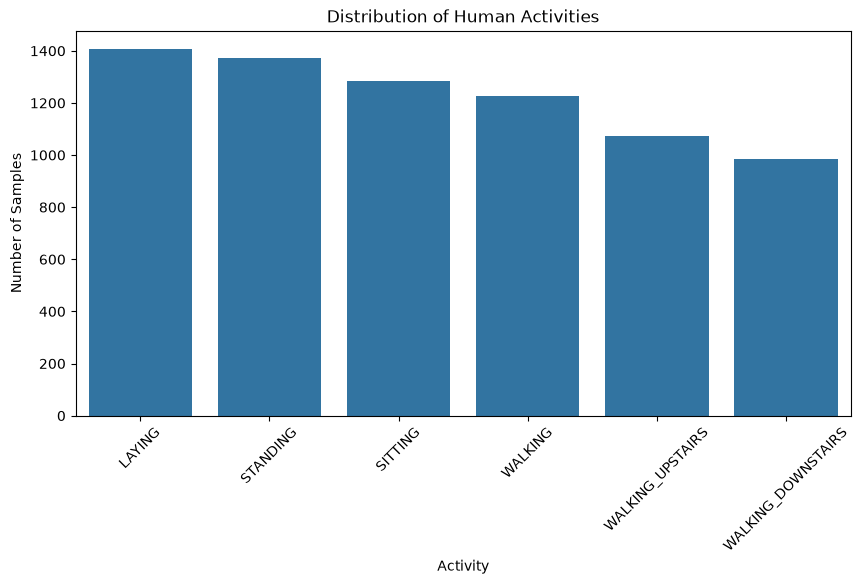

In [47]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=activity_distribution,
    x="activity",
    y="count"
)

plt.xticks(rotation=45)
plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")

plt.show()

In [48]:
y_train = y_train["activity"]
y_test = y_test["activity"]

In [49]:
print(x_train.shape)
print(x_test.shape)

print(y_train.shape)
print(y_test.shape)

(7352, 561)
(2947, 561)
(7352,)
(2947,)
